In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 코랩 환경 한글 깨짐 방지 폰트 설치
!sudo apt-get install -y fonts-nanum
!fc-cache -fv
!rm ~/.cache/matplotlib -rf

plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

print("설정 완료!")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/u

In [ ]:
file_path = '귀화예측_상위10컬럼.csv'
df = pd.read_csv(file_path)

print("전체 데이터 형태 (행, 열):", df.shape)
display(df.head(5))

전체 데이터 형태 (행, 열): (17933, 11)


,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
0,2012.0,9.0,4.0,34.0,122.0,2.0,2.0,1.0,1.0,1.0,1.0
1,2007.0,12.0,2.0,40.0,185.0,1.0,2.0,1.0,1.0,1.0,1.0
2,2010.0,12.0,2.0,34.0,155.0,1.0,2.0,1.0,1.0,1.0,0.0
3,2005.0,9.0,2.0,35.0,185.0,1.0,2.0,1.0,1.0,1.0,1.0
4,2011.0,16.0,2.0,31.0,122.0,1.0,2.0,1.0,1.0,1.0,1.0


In [ ]:
target_col = '국적취득여부'

# 식별자나 가중치 등 피처로 사용하지 않을 컬럼 제외
drop_cols = [col for col in ['가구ID', '가중치', target_col] if col in df.columns]

X = df.drop(columns=drop_cols)
y = df[target_col]

# dropna() 없이 결측치를 특수 값(-999, -1)으로 채워 모든 행(데이터 손실 0%) 유지
X_imputed = X.fillna(-999)
y_imputed = y.fillna(-1)

print(f"원본 행 개수 (삭제 없음): {len(df)}개")
print(f"학습에 사용되는 특성(Feature) 개수: {X.shape[1]}개")

원본 행 개수 (삭제 없음): 17933개
학습에 사용되는 특성(Feature) 개수: 10개


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y_imputed,
    test_size=0.2,
    random_state=42
)

print(f"학습용 데이터 크기: {X_train.shape}")
print(f"테스트용 데이터 크기: {X_test.shape}")

학습용 데이터 크기: (14346, 10)
테스트용 데이터 크기: (3587, 10)


In [ ]:
# 과소적합 해결을 위한 모델 설정 변경
rf_model = RandomForestClassifier(
    n_estimators=200,   # 트리 개수 늘리기
    max_depth=None,     # 깊이 제한 해제 (더 복잡한 패턴 학습)
    min_samples_split=2,# 노드를 분할하기 위한 최소 샘플 수 조절
    random_state=42
)

rf_model.fit(X_train, y_train)
print("과소적합 보완용 랜덤 포레스트 모델 학습 완료!")

과소적합 보완용 랜덤 포레스트 모델 학습 완료!


In [ ]:
y_pred = rf_model.predict(X_test)

print("=" * 50)
print(f"정확도 (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("=" * 50)
print("\n[분류 보고서]")
print(classification_report(y_test, y_pred))

#정확도=> 가중치 포함: 0.7608 / 가중치 미포함: 0.7608

정확도 (Accuracy): 0.7608

[분류 보고서]
              precision    recall  f1-score   support

         0.0       0.76      0.74      0.75      1724
         1.0       0.76      0.78      0.77      1863

    accuracy                           0.76      3587
   macro avg       0.76      0.76      0.76      3587
weighted avg       0.76      0.76      0.76      3587



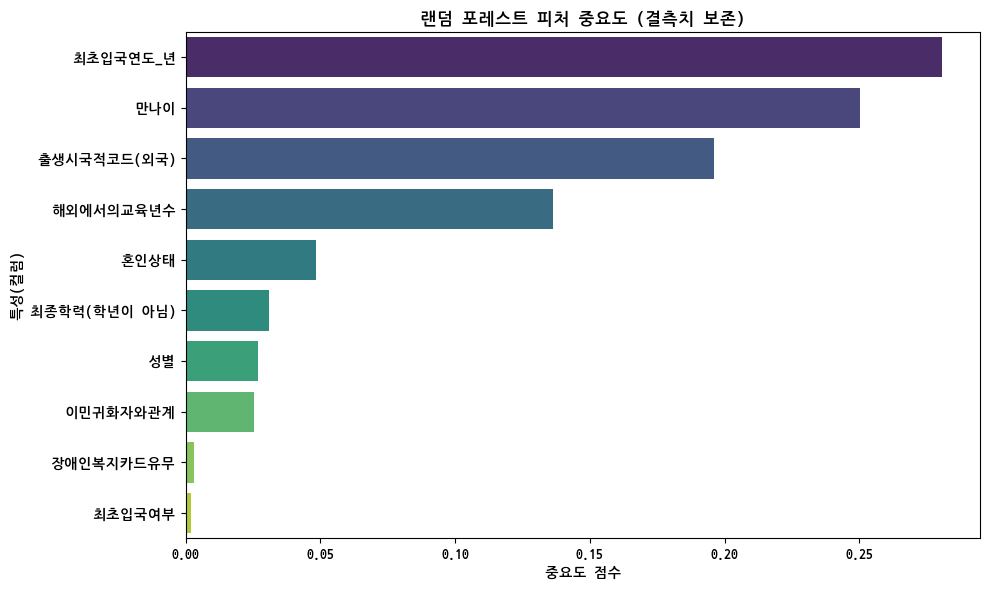

In [ ]:
import matplotlib.font_manager as fm
import os

# 나눔 폰트 경로 직접 탐색 및 등록
font_list = fm.findSystemFonts(fontpaths=None, fontext='ttf')
nanum_fonts = [f for f in font_list if 'Nanum' in f]

if nanum_fonts:
    # 첫 번째 나눔 폰트를 기본 폰트로 설정
    fm.fontManager.addfont(nanum_fonts[0])
    font_name = fm.FontProperties(fname=nanum_fonts[0]).get_name()
    plt.rc('font', family=font_name)
else:
    # 시스템 기본 한글 폰트 설정 시도
    plt.rc('font', family='NanumGothic')

plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# [셀 7] 피처 중요도(Feature Importance) 시각화
# ==========================================
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importances = feature_importances.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=feature_importances.values,
    y=feature_importances.index,
    hue=feature_importances.index,
    palette='viridis',
    legend=False
)
plt.title('랜덤 포레스트 피처 중요도 (결측치 보존)')
plt.xlabel('중요도 점수')
plt.ylabel('특성(컬럼)')
plt.tight_layout()
plt.show()